In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import zipfile
import os

from pathlib import Path

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from pathlib import Path
import zipfile

# Define project directory
PROJECT_DIR = Path.cwd()

RAW_DIR = PROJECT_DIR / "dataset"
PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"

# Create directories
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# ZIP file location
zip_path = RAW_DIR / "olist_brazilian_ecommerce.zip"

print("Project directory:", PROJECT_DIR)
print("ZIP file exists:", zip_path.exists())
print("ZIP file path:", zip_path)

Project directory: C:\Users\konic\Olist_Capstone_Analysis
ZIP file exists: True
ZIP file path: C:\Users\konic\Olist_Capstone_Analysis\dataset\olist_brazilian_ecommerce.zip


In [5]:
EXTRACT_DIR = RAW_DIR / "extracted"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
csv_files = list(EXTRACT_DIR.glob("*.csv"))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Total CSV files: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [7]:
import pandas as pd
import numpy as np
from pathlib import Path
import os

In [8]:
PROJECT_DIR = Path.cwd()
EXTRACT_DIR = PROJECT_DIR / "dataset" / "extracted"

print("Dataset folder:", EXTRACT_DIR)
print("Folder exists:", EXTRACT_DIR.exists())

Dataset folder: C:\Users\konic\Olist_Capstone_Analysis\dataset\extracted
Folder exists: True


In [9]:
customers = pd.read_csv(EXTRACT_DIR / "olist_customers_dataset.csv")
geolocation = pd.read_csv(EXTRACT_DIR / "olist_geolocation_dataset.csv")
orders = pd.read_csv(EXTRACT_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(EXTRACT_DIR / "olist_order_items_dataset.csv")
payments = pd.read_csv(EXTRACT_DIR / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(EXTRACT_DIR / "olist_order_reviews_dataset.csv")
products = pd.read_csv(EXTRACT_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(EXTRACT_DIR / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(EXTRACT_DIR / "product_category_name_translation.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [10]:
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name:22} | Rows: {df.shape[0]:>9,} | Columns: {df.shape[1]}")

Customers              | Rows:    99,441 | Columns: 5
Geolocation            | Rows: 1,000,163 | Columns: 5
Orders                 | Rows:    99,441 | Columns: 8
Order Items            | Rows:   112,650 | Columns: 7
Payments               | Rows:   103,886 | Columns: 5
Reviews                | Rows:    99,224 | Columns: 7
Products               | Rows:    32,951 | Columns: 9
Sellers                | Rows:     3,095 | Columns: 4
Category Translation   | Rows:        71 | Columns: 2


In [11]:
for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(name)
    print("="*60)
    print(df.info())


Customers
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB
None

Geolocation
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city  

In [12]:
missing_summary = []

for name, df in datasets.items():
    for column in df.columns:
        missing_count = df[column].isnull().sum()

        if missing_count > 0:
            missing_summary.append({
                "Dataset": name,
                "Column": column,
                "Missing Values": missing_count,
                "Missing Percentage": round(
                    (missing_count / len(df)) * 100, 2
                )
            })

missing_df = pd.DataFrame(missing_summary)

missing_df.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Dataset,Column,Missing Values,Missing Percentage
3,Reviews,review_comment_title,87656,88.34
4,Reviews,review_comment_message,58247,58.70
2,Orders,order_delivered_customer_date,2965,2.98
5,Products,product_category_name,610,1.85
6,Products,product_name_lenght,610,1.85
7,Products,product_description_lenght,610,1.85
8,Products,product_photos_qty,610,1.85
1,Orders,order_delivered_carrier_date,1783,1.79
0,Orders,order_approved_at,160,0.16
9,Products,product_weight_g,2,0.01


In [13]:
print("FULL ROW DUPLICATES")
print("-" * 40)

for name, df in datasets.items():
    print(f"{name:22} | {df.duplicated().sum():,} duplicates")

FULL ROW DUPLICATES
----------------------------------------
Customers              | 0 duplicates
Geolocation            | 261,831 duplicates
Orders                 | 0 duplicates
Order Items            | 0 duplicates
Payments               | 0 duplicates
Reviews                | 0 duplicates
Products               | 0 duplicates
Sellers                | 0 duplicates
Category Translation   | 0 duplicates


In [14]:
key_checks = {
    "Customers": (customers, ["customer_id"]),
    "Orders": (orders, ["order_id"]),
    "Products": (products, ["product_id"]),
    "Sellers": (sellers, ["seller_id"]),
    "Reviews": (reviews, ["review_id"]),
    "Category Translation": (
        category_translation, ["product_category_name"]
    ),
    "Order Items": (order_items, ["order_id", "order_item_id"]),
    "Payments": (payments, ["order_id", "payment_sequential"])
}

for name, (df, keys) in key_checks.items():
    duplicate_count = df.duplicated(subset=keys).sum()

    print(
        f"{name:22} | Duplicate key combinations: "
        f"{duplicate_count:,}"
    )

Customers              | Duplicate key combinations: 0
Orders                 | Duplicate key combinations: 0
Products               | Duplicate key combinations: 0
Sellers                | Duplicate key combinations: 0
Reviews                | Duplicate key combinations: 814
Category Translation   | Duplicate key combinations: 0
Order Items            | Duplicate key combinations: 0
Payments               | Duplicate key combinations: 0


In [15]:
print("Order Status vs Missing Delivery Date")
print("-" * 50)

delivery_missing = orders.groupby("order_status").agg(
    Total_Orders=("order_id", "count"),
    Missing_Delivery_Date=(
        "order_delivered_customer_date",
        lambda x: x.isnull().sum()
    )
)

delivery_missing["Missing_Percentage"] = (
    delivery_missing["Missing_Delivery_Date"]
    / delivery_missing["Total_Orders"] * 100
).round(2)

delivery_missing

Order Status vs Missing Delivery Date
--------------------------------------------------


,Total_Orders,Missing_Delivery_Date,Missing_Percentage
order_status,,,
approved,2,2,100.00
canceled,625,619,99.04
created,5,5,100.00
delivered,96478,8,0.01
invoiced,314,314,100.00
processing,301,301,100.00
shipped,1107,1107,100.00
unavailable,609,609,100.00


In [16]:
print("Total geolocation records:", len(geolocation))

print(
    "Completely duplicated rows:",
    geolocation.duplicated().sum()
)

print(
    "Repeated ZIP code prefixes:",
    geolocation["geolocation_zip_code_prefix"].duplicated().sum()
)

Total geolocation records: 1000163
Completely duplicated rows: 261831
Repeated ZIP code prefixes: 981148


In [17]:
duplicate_reviews = reviews[
    reviews.duplicated(subset=["review_id"], keep=False)
].sort_values("review_id")

print("Records with repeated review IDs:", len(duplicate_reviews))

duplicate_reviews.head(20)

Records with repeated review IDs: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [18]:
duplicate_reviews.groupby("review_id").agg(
    Number_of_Records=("order_id", "count"),
    Unique_Orders=("order_id", "nunique"),
    Review_Scores=("review_score", "nunique")
).head(20)

,Number_of_Records,Unique_Orders,Review_Scores
review_id,,,
00130cbe1f9d422698c812ed8ded1919,2,2,1
0115633a9c298b6a98bcbe4eee75345f,2,2,1
0174caf0ee5964646040cd94e15ac95e,2,2,1
017808d29fd1f942d97e50184dfb4c13,2,2,1
0254bd905dc677a6078990aad3331a36,2,2,1
0288d42bef3dfe36930740c9588a570f,2,2,1
02aa7f5f75e964e3c7efa59a1f515281,2,2,1
034528cb00b6bc981847acafbdf2ae0b,2,2,1
03a6a25db577d0689440933055111897,2,2,1


In [19]:
date_columns = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "order_items": ["shipping_limit_date"],
    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

orders_clean = orders.copy()
order_items_clean = order_items.copy()
reviews_clean = reviews.copy()

for column in date_columns["orders"]:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column], errors="coerce"
    )

for column in date_columns["order_items"]:
    order_items_clean[column] = pd.to_datetime(
        order_items_clean[column], errors="coerce"
    )

for column in date_columns["reviews"]:
    reviews_clean[column] = pd.to_datetime(
        reviews_clean[column], errors="coerce"
    )

print("Date conversion completed!")
print(orders_clean.dtypes)

Date conversion completed!
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [20]:
products_clean = products.copy()

products_clean["product_category_name"] = (
    products_clean["product_category_name"].fillna("Unknown")
)

print(
    "Missing product categories after cleaning:",
    products_clean["product_category_name"].isnull().sum()
)

Missing product categories after cleaning: 0


In [21]:
geolocation_clean = geolocation.drop_duplicates().copy()

print("Original geolocation rows:", len(geolocation))
print("Cleaned geolocation rows:", len(geolocation_clean))
print(
    "Exact duplicates remaining:",
    geolocation_clean.duplicated().sum()
)

Original geolocation rows: 1000163
Cleaned geolocation rows: 738332
Exact duplicates remaining: 0


In [22]:
print("ORDER DATE VALIDATION")
print("-" * 45)

for column in date_columns["orders"]:
    print(f"{column}: {orders_clean[column].isna().sum()}")

print("\nORDER ITEM DATE VALIDATION")

for column in date_columns["order_items"]:
    print(f"{column}: {order_items_clean[column].isna().sum()}")

print("\nREVIEW DATE VALIDATION")

for column in date_columns["reviews"]:
    print(f"{column}: {reviews_clean[column].isna().sum()}")

ORDER DATE VALIDATION
---------------------------------------------
order_purchase_timestamp: 0
order_approved_at: 160
order_delivered_carrier_date: 1783
order_delivered_customer_date: 2965
order_estimated_delivery_date: 0

ORDER ITEM DATE VALIDATION
shipping_limit_date: 0

REVIEW DATE VALIDATION
review_creation_date: 0
review_answer_timestamp: 0


In [23]:
repeated_review_ids = reviews_clean[
    reviews_clean.duplicated(
        subset=["review_id"],
        keep=False
    )
].sort_values("review_id")

print("Rows with repeated review IDs:", len(repeated_review_ids))

display(repeated_review_ids.head(10))

Rows with repeated review IDs: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44


In [24]:
print("INVALID / MISSING DATE CHECK")
print("-" * 50)

for column in date_columns["orders"]:
    print(
        f"{column}:",
        orders_clean[column].isna().sum()
    )

for column in date_columns["order_items"]:
    print(
        f"{column}:",
        order_items_clean[column].isna().sum()
    )

for column in date_columns["reviews"]:
    print(
        f"{column}:",
        reviews_clean[column].isna().sum()
    )

INVALID / MISSING DATE CHECK
--------------------------------------------------
order_purchase_timestamp: 0
order_approved_at: 160
order_delivered_carrier_date: 1783
order_delivered_customer_date: 2965
order_estimated_delivery_date: 0
shipping_limit_date: 0
review_creation_date: 0
review_answer_timestamp: 0


In [25]:
products_clean.isnull().sum()

product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [26]:
print("ORDER DATE VALIDATION")
print("-" * 45)

for column in date_columns["orders"]:
    print(f"{column}: {orders_clean[column].isna().sum()}")

print("\nORDER ITEM DATE VALIDATION")

for column in date_columns["order_items"]:
    print(f"{column}: {order_items_clean[column].isna().sum()}")

print("\nREVIEW DATE VALIDATION")

for column in date_columns["reviews"]:
    print(f"{column}: {reviews_clean[column].isna().sum()}")

ORDER DATE VALIDATION
---------------------------------------------
order_purchase_timestamp: 0
order_approved_at: 160
order_delivered_carrier_date: 1783
order_delivered_customer_date: 2965
order_estimated_delivery_date: 0

ORDER ITEM DATE VALIDATION
shipping_limit_date: 0

REVIEW DATE VALIDATION
review_creation_date: 0
review_answer_timestamp: 0


In [27]:
repeated_review_ids = reviews_clean[
    reviews_clean.duplicated(
        subset=["review_id"],
        keep=False
    )
].sort_values("review_id")

print("Rows with repeated review IDs:", len(repeated_review_ids))

display(repeated_review_ids.head(10))

Rows with repeated review IDs: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44


In [28]:
products_clean.isnull().sum()

product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [29]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

customers.to_csv(PROCESSED_DIR / "customers_clean.csv", index=False)
orders_clean.to_csv(PROCESSED_DIR / "orders_clean.csv", index=False)
order_items_clean.to_csv(PROCESSED_DIR / "order_items_clean.csv", index=False)
payments.to_csv(PROCESSED_DIR / "payments_clean.csv", index=False)
reviews_clean.to_csv(PROCESSED_DIR / "reviews_clean.csv", index=False)
products_clean.to_csv(PROCESSED_DIR / "products_clean.csv", index=False)
sellers.to_csv(PROCESSED_DIR / "sellers_clean.csv", index=False)
geolocation_clean.to_csv(PROCESSED_DIR / "geolocation_clean.csv", index=False)
category_translation.to_csv(PROCESSED_DIR / "category_translation_clean.csv", index=False)

print("All cleaned datasets saved successfully!")

All cleaned datasets saved successfully!


In [30]:
delivery_analysis = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].notna()) &
    (orders_clean["order_purchase_timestamp"].notna()) &
    (orders_clean["order_estimated_delivery_date"].notna())
].copy()

print("Total delivered orders:", 
      (orders_clean["order_status"] == "delivered").sum())

print("Valid orders for delivery analysis:", len(delivery_analysis))

print("Excluded delivered orders:",
      (orders_clean["order_status"] == "delivered").sum()
      - len(delivery_analysis))

Total delivered orders: 96478
Valid orders for delivery analysis: 96470
Excluded delivered orders: 8


In [31]:
delivery_analysis["actual_delivery_days"] = (
    delivery_analysis["order_delivered_customer_date"]
    - delivery_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_analysis["estimated_delivery_days"] = (
    delivery_analysis["order_estimated_delivery_date"]
    - delivery_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_analysis["delivery_delay_days"] = (
    delivery_analysis["order_delivered_customer_date"]
    - delivery_analysis["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery_analysis["delivery_status"] = np.where(
    delivery_analysis["delivery_delay_days"] > 0,
    "Late",
    "On Time or Early"
)

delivery_analysis[
    [
        "order_id",
        "actual_delivery_days",
        "estimated_delivery_days",
        "delivery_delay_days",
        "delivery_status"
    ]
].head(10)

,order_id,actual_delivery_days,estimated_delivery_days,delivery_delay_days,delivery_status
0,e481f51cbdc54678b7cc49136f2d6af7,8.44,15.54,-7.11,On Time or Early
1,53cdb2fc8bc7dce0b6741e2150273451,13.78,19.14,-5.36,On Time or Early
2,47770eb9100c2d0c44946d9cf07ec65d,9.39,26.64,-17.25,On Time or Early
3,949d5b44dbf5de918fe9c16f97b45f8a,13.21,26.19,-12.98,On Time or Early
4,ad21c59c0840e6cb83a9ceb5573f8159,2.87,12.11,-9.24,On Time or Early
5,a4591c265e18cb1dcee52889e2d8acc3,16.54,22.09,-5.54,On Time or Early
7,6514b8ad8028c9f2cc2374ded245783f,9.99,21.45,-11.46,On Time or Early
8,76c6e866289321a7c93b82b54852dc33,9.82,41.23,-31.41,On Time or Early
9,e69bfb5eb88e0ed6a785585b27e16dbf,18.22,24.50,-6.28,On Time or Early
10,e6ce16cb79ec1d90b1da9085a6118aeb,12.65,21.18,-8.53,On Time or Early


In [32]:
delivery_kpis = {
    "Total Delivered Orders": len(delivery_analysis),
    "Average Delivery Days": round(
        delivery_analysis["actual_delivery_days"].mean(), 2
    ),
    "Average Delivery Delay": round(
        delivery_analysis["delivery_delay_days"].mean(), 2
    ),
    "Late Delivery Percentage": round(
        (delivery_analysis["delivery_status"] == "Late").mean() * 100, 2
    ),
    "On Time or Early Percentage": round(
        (delivery_analysis["delivery_status"] == "On Time or Early").mean() * 100, 2
    )
}

pd.Series(delivery_kpis)

Total Delivered Orders        96470.00
Average Delivery Days            12.56
Average Delivery Delay          -11.18
Late Delivery Percentage          8.11
On Time or Early Percentage      91.89
dtype: float64

In [33]:
review_id_summary = (
    reviews_clean
    .groupby("review_id")
    .agg(
        order_count=("order_id", "nunique"),
        score_count=("review_score", "nunique"),
        comment_count=("review_comment_message", "nunique"),
        total_records=("order_id", "size")
    )
    .reset_index()
)

repeated_review_summary = review_id_summary[
    review_id_summary["total_records"] > 1
]

print("Repeated review IDs:",
      len(repeated_review_summary))

print("\nRecords associated with repeated review IDs:",
      repeated_review_summary["total_records"].sum())

display(repeated_review_summary.head(10))

Repeated review IDs: 789

Records associated with repeated review IDs: 1603


,review_id,order_count,score_count,comment_count,total_records
31,00130cbe1f9d422698c812ed8ded1919,2,1,1,2
425,0115633a9c298b6a98bcbe4eee75345f,2,1,0,2
568,0174caf0ee5964646040cd94e15ac95e,2,1,1,2
574,017808d29fd1f942d97e50184dfb4c13,2,1,0,2
884,0254bd905dc677a6078990aad3331a36,2,1,1,2
961,0288d42bef3dfe36930740c9588a570f,2,1,0,2
1000,02aa7f5f75e964e3c7efa59a1f515281,2,1,0,2
1225,034528cb00b6bc981847acafbdf2ae0b,2,1,0,2
1364,03a6a25db577d0689440933055111897,2,1,1,2
1674,0467560f511c516ddaa54a60edb0c291,2,1,0,2


In [34]:
review_consistency = (
    reviews_clean
    .groupby("review_id")
    .agg(
        unique_orders=("order_id", "nunique"),
        unique_scores=("review_score", "nunique"),
        unique_messages=("review_comment_message",
                         lambda x: x.nunique(dropna=False))
    )
    .reset_index()
)

print("Repeated IDs with different scores:",
      len(review_consistency[
          (review_consistency["unique_orders"] > 1) &
          (review_consistency["unique_scores"] > 1)
      ]))

print("Repeated IDs with different messages:",
      len(review_consistency[
          (review_consistency["unique_orders"] > 1) &
          (review_consistency["unique_messages"] > 1)
      ]))

Repeated IDs with different scores: 0
Repeated IDs with different messages: 0


In [35]:
review_check = (
    reviews_clean
    .groupby("review_id")
    .agg(
        total_records=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        unique_scores=("review_score", "nunique"),
        unique_messages=(
            "review_comment_message",
            lambda x: x.nunique(dropna=False)
        )
    )
    .reset_index()
)

repeated_reviews = review_check[
    review_check["total_records"] > 1
]

print("Repeated review IDs:", len(repeated_reviews))

print(
    "Repeated IDs with different scores:",
    (repeated_reviews["unique_scores"] > 1).sum()
)

print(
    "Repeated IDs with different messages:",
    (repeated_reviews["unique_messages"] > 1).sum()
)

print(
    "Repeated IDs associated with multiple orders:",
    (repeated_reviews["unique_orders"] > 1).sum()
)

Repeated review IDs: 789
Repeated IDs with different scores: 0
Repeated IDs with different messages: 0
Repeated IDs associated with multiple orders: 789


In [36]:
products_clean.isnull().sum()

product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [37]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

cleaned_datasets = {
    "customers_clean": customers,
    "orders_clean": orders_clean,
    "order_items_clean": order_items_clean,
    "payments_clean": payments,
    "reviews_clean": reviews_clean,
    "products_clean": products_clean,
    "sellers_clean": sellers,
    "geolocation_clean": geolocation_clean,
    "category_translation_clean": category_translation
}

for name, df in cleaned_datasets.items():
    df.to_csv(PROCESSED_DIR / f"{name}.csv", index=False)

print("All 9 cleaned datasets saved successfully!")

All 9 cleaned datasets saved successfully!


In [38]:
# Basic business metrics

total_orders = orders_clean["order_id"].nunique()

total_customers = customers["customer_unique_id"].nunique()

total_products = products_clean["product_id"].nunique()

total_sellers = sellers["seller_id"].nunique()

total_revenue = order_items_clean["price"].sum()

average_order_value = (
    order_items_clean.groupby("order_id")["price"]
    .sum()
    .mean()
)

average_review_score = reviews_clean["review_score"].mean()

print("========== OLIST BUSINESS OVERVIEW ==========")

print("Total Orders:", f"{total_orders:,}")
print("Unique Customers:", f"{total_customers:,}")
print("Total Products:", f"{total_products:,}")
print("Total Sellers:", f"{total_sellers:,}")
print("Total Item Revenue:", f"R$ {total_revenue:,.2f}")
print("Average Order Value:", f"R$ {average_order_value:,.2f}")
print("Average Review Score:", round(average_review_score, 2))

========== OLIST BUSINESS OVERVIEW ==========
Total Orders: 99,441
Unique Customers: 96,096
Total Products: 32,951
Total Sellers: 3,095
Total Item Revenue: R$ 13,591,643.70
Average Order Value: R$ 137.75
Average Review Score: 4.09


In [39]:
# Aggregate order items before joining to orders
order_item_summary = (
    order_items_clean
    .groupby("order_id")
    .agg(
        item_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
)

# Merge with orders (one row per order)
order_overview = orders_clean.merge(
    order_item_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Rows in order overview:", len(order_overview))
print("Unique orders:", order_overview["order_id"].nunique())

display(order_overview.head())

Rows in order overview: 99441
Unique orders: 99441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,item_revenue,freight_revenue,total_items
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,29.99,8.72,1.00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,118.70,22.76,1.00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,159.90,19.22,1.00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,45.00,27.20,1.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,19.90,8.72,1.00


In [40]:
status_analysis = (
    order_overview
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique"),
        item_revenue=("item_revenue", "sum")
    )
    .sort_values("total_orders", ascending=False)
)

status_analysis["order_percentage"] = (
    status_analysis["total_orders"]
    / status_analysis["total_orders"].sum() * 100
).round(2)

status_analysis

,total_orders,item_revenue,order_percentage
order_status,,,
delivered,96478,13221498.11,97.02
shipped,1107,150727.44,1.11
canceled,625,95235.27,0.63
unavailable,609,2007.69,0.61
invoiced,314,61526.37,0.32
processing,301,60439.22,0.30
created,5,0.00,0.01
approved,2,209.60,0.00


In [41]:
delivered_orders = order_overview[
    (order_overview["order_status"] == "delivered") &
    (order_overview["order_purchase_timestamp"].notna())
].copy()

delivered_orders["purchase_month"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.to_period("M").astype(str)
)

monthly_sales = (
    delivered_orders
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        revenue=("item_revenue", "sum")
    )
    .reset_index()
)

monthly_sales.head(15)

,purchase_month,total_orders,revenue
0,2016-09,1,134.97
1,2016-10,265,40325.11
2,2016-12,1,10.90
3,2017-01,750,111798.36
4,2017-02,1653,234223.40
5,2017-03,2546,359198.85
6,2017-04,2303,340669.68
7,2017-05,3546,489338.25
8,2017-06,3135,421923.37
9,2017-07,3872,481604.52


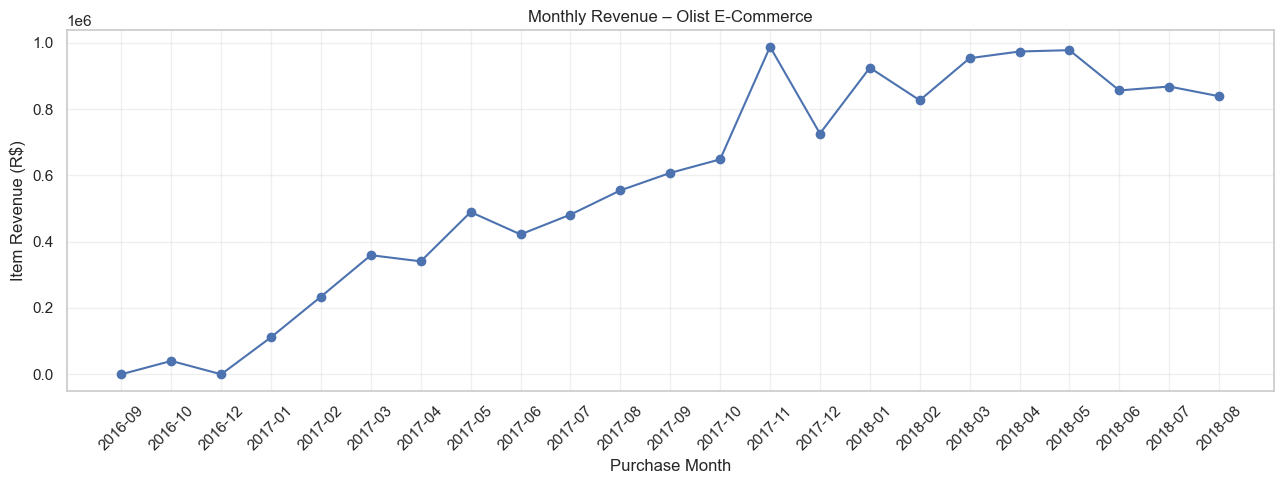

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["revenue"],
    marker="o"
)

plt.title("Monthly Revenue – Olist E-Commerce")
plt.xlabel("Purchase Month")
plt.ylabel("Item Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
# Convert purchase_month into a monthly datetime index
monthly_sales["purchase_month"] = pd.to_datetime(
    monthly_sales["purchase_month"]
)

# Create a complete monthly date range
all_months = pd.date_range(
    start=monthly_sales["purchase_month"].min(),
    end=monthly_sales["purchase_month"].max(),
    freq="MS"
)

# Reindex to include missing months
monthly_sales_complete = (
    monthly_sales
    .set_index("purchase_month")
    .reindex(all_months, fill_value=0)
    .rename_axis("purchase_month")
    .reset_index()
)

# Display the updated table
monthly_sales_complete.head(15)

,purchase_month,total_orders,revenue
0,2016-09-01,1,134.97
1,2016-10-01,265,40325.11
2,2016-11-01,0,0.00
3,2016-12-01,1,10.90
4,2017-01-01,750,111798.36
5,2017-02-01,1653,234223.40
6,2017-03-01,2546,359198.85
7,2017-04-01,2303,340669.68
8,2017-05-01,3546,489338.25
9,2017-06-01,3135,421923.37


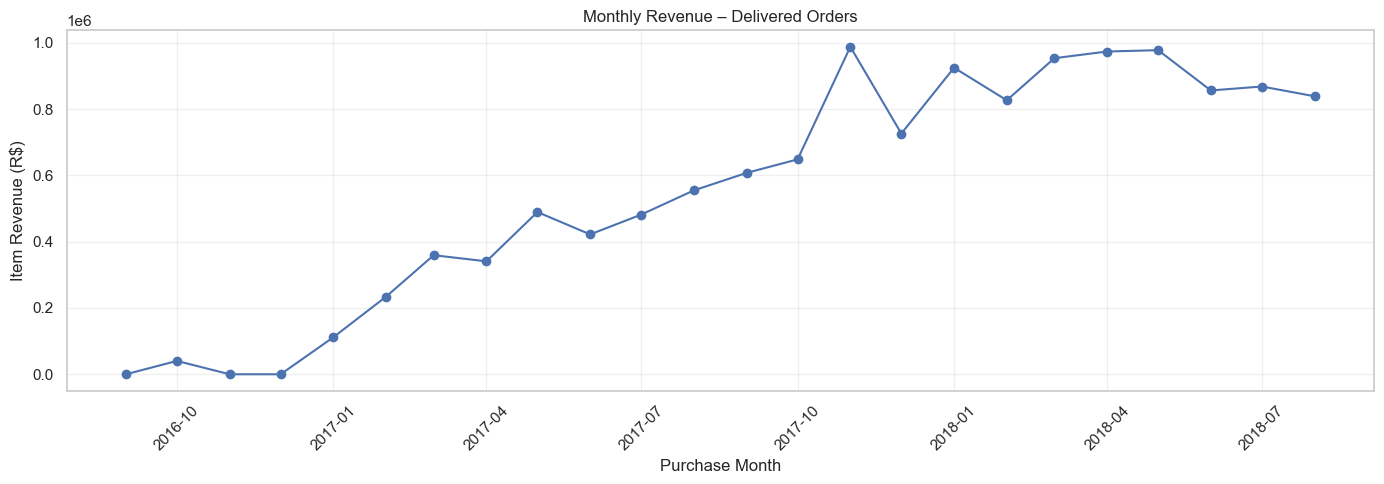

In [44]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales_complete["purchase_month"],
    monthly_sales_complete["revenue"],
    marker="o"
)

plt.title("Monthly Revenue – Delivered Orders")
plt.xlabel("Purchase Month")
plt.ylabel("Item Revenue (R$)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
import numpy as np

delivery_analysis = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].notna()) &
    (orders_clean["order_purchase_timestamp"].notna()) &
    (orders_clean["order_estimated_delivery_date"].notna())
].copy()

# Calculate actual delivery time
delivery_analysis["actual_delivery_days"] = (
    delivery_analysis["order_delivered_customer_date"] -
    delivery_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate estimated delivery time
delivery_analysis["estimated_delivery_days"] = (
    delivery_analysis["order_estimated_delivery_date"] -
    delivery_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate delivery delay
delivery_analysis["delivery_delay_days"] = (
    delivery_analysis["order_delivered_customer_date"] -
    delivery_analysis["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Classify delivery performance
delivery_analysis["delivery_status"] = np.where(
    delivery_analysis["delivery_delay_days"] > 0,
    "Late",
    "On Time or Early"
)

delivery_analysis.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,estimated_delivery_days,delivery_delay_days,delivery_status
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,15.54,-7.11,On Time or Early
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,19.14,-5.36,On Time or Early
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,26.64,-17.25,On Time or Early
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,26.19,-12.98,On Time or Early
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,12.11,-9.24,On Time or Early


In [46]:
delivery_kpis = {
    "Total Delivered Orders": len(delivery_analysis),

    "Average Delivery Time (Days)": 
        delivery_analysis["actual_delivery_days"].mean(),

    "Average Delivery Delay (Days)": 
        delivery_analysis["delivery_delay_days"].mean(),

    "Late Deliveries (%)": 
        (delivery_analysis["delivery_status"].eq("Late").mean() * 100),

    "On-Time or Early Deliveries (%)": 
        (delivery_analysis["delivery_status"].eq("On Time or Early").mean() * 100)
}

pd.Series(delivery_kpis).round(2)

Total Delivered Orders            96470.00
Average Delivery Time (Days)         12.56
Average Delivery Delay (Days)       -11.18
Late Deliveries (%)                   8.11
On-Time or Early Deliveries (%)      91.89
dtype: float64

In [47]:
# Aggregate review scores at order level
review_order_summary = (
    reviews_clean
    .groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    .reset_index()
)

# Merge review scores with delivery analysis
delivery_reviews = delivery_analysis.merge(
    review_order_summary,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

print("Orders with delivery and review data:",
      len(delivery_reviews))

display(delivery_reviews.head())

Orders with delivery and review data: 95824


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,estimated_delivery_days,delivery_delay_days,delivery_status,average_review_score,review_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,15.54,-7.11,On Time or Early,4.00,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,19.14,-5.36,On Time or Early,4.00,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,26.64,-17.25,On Time or Early,5.00,1
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,26.19,-12.98,On Time or Early,5.00,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,12.11,-9.24,On Time or Early,5.00,1


In [48]:
# Compare customer ratings by delivery performance
satisfaction_analysis = (
    delivery_reviews
    .groupby("delivery_status")
    .agg(
        total_orders=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean"),
        median_review_score=("average_review_score", "median")
    )
    .round(2)
)

satisfaction_analysis

,total_orders,average_review_score,median_review_score
delivery_status,,,
Late,7661,2.57,2.00
On Time or Early,88163,4.29,5.00


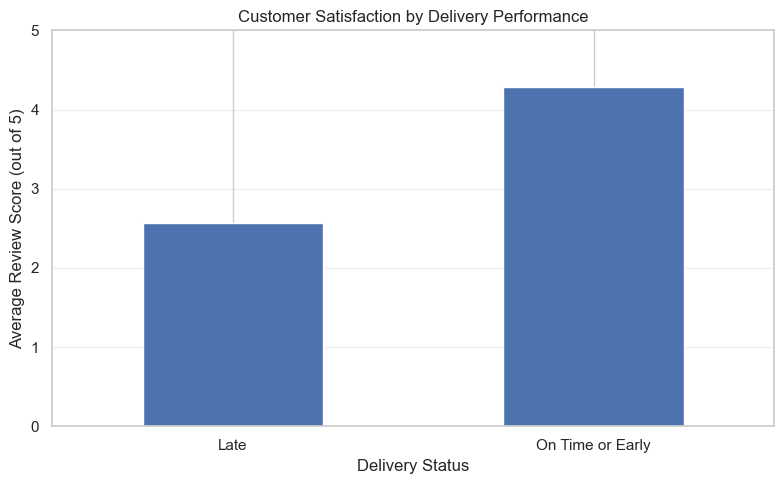

In [49]:
satisfaction_analysis["average_review_score"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Customer Satisfaction by Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [50]:
from scipy.stats import mannwhitneyu

# Separate review scores into two groups
late_scores = delivery_reviews.loc[
    delivery_reviews["delivery_status"] == "Late",
    "average_review_score"
]

ontime_scores = delivery_reviews.loc[
    delivery_reviews["delivery_status"] == "On Time or Early",
    "average_review_score"
]

# Perform Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    late_scores,
    ontime_scores,
    alternative="less"
)

# Display results
print("MANN-WHITNEY U TEST RESULTS")
print("--------------------------------")
print("Late delivery orders:", len(late_scores))
print("On-time/early orders:", len(ontime_scores))
print("U Statistic:", round(u_statistic, 2))
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis (H0)")
    print("Conclusion: Late deliveries are associated with lower review scores.")
else:
    print("\nDecision: Fail to reject the Null Hypothesis (H0)")
    print("Conclusion: Insufficient statistical evidence of lower scores for late deliveries.")

MANN-WHITNEY U TEST RESULTS
--------------------------------
Late delivery orders: 7661
On-time/early orders: 88163
U Statistic: 150680825.5
P-value: 0.0

Decision: Reject the Null Hypothesis (H0)
Conclusion: Late deliveries are associated with lower review scores.


In [51]:
# Translate product category names
products_category = products_clean.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Attach category information to order items
items_category = order_items_clean.merge(
    products_category[
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Analyze category revenue and order volume
category_analysis = (
    items_category
    .groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        total_items=("order_item_id", "count"),
        average_item_price=("price", "mean")
    )
    .sort_values("total_revenue", ascending=False)
    .round(2)
)

category_analysis.head(15)

,total_revenue,total_items,average_item_price
product_category_name_english,,,
health_beauty,1258681.34,9670,130.16
watches_gifts,1205005.68,5991,201.14
bed_bath_table,1036988.68,11115,93.30
sports_leisure,988048.97,8641,114.34
computers_accessories,911954.32,7827,116.51
furniture_decor,729762.49,8334,87.56
cool_stuff,635290.85,3796,167.36
housewares,632248.66,6964,90.79
auto,592720.11,4235,139.96


In [52]:
# Get IDs of successfully delivered orders
delivered_order_ids = orders_clean.loc[
    orders_clean["order_status"] == "delivered",
    "order_id"
]

# Keep only items belonging to delivered orders
delivered_items_category = items_category[
    items_category["order_id"].isin(delivered_order_ids)
].copy()

# Recalculate category performance
delivered_category_analysis = (
    delivered_items_category
    .groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        total_items=("order_item_id", "count"),
        average_item_price=("price", "mean")
    )
    .sort_values("total_revenue", ascending=False)
    .round(2)
)

delivered_category_analysis.head(15)

,total_revenue,total_items,average_item_price
product_category_name_english,,,
health_beauty,1233131.72,9465,130.28
watches_gifts,1166176.98,5859,199.04
bed_bath_table,1023434.76,10953,93.44
sports_leisure,954852.55,8431,113.25
computers_accessories,888724.61,7644,116.26
furniture_decor,711927.69,8160,87.25
housewares,615628.69,6795,90.60
cool_stuff,610204.10,3718,164.12
auto,578966.65,4140,139.85


In [53]:
# Analyze seller performance using delivered orders only

seller_analysis = (
    delivered_items_category
    .groupby("seller_id")
    .agg(
        total_revenue=("price", "sum"),
        total_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        average_item_price=("price", "mean")
    )
    .reset_index()
)

# Add seller location information
seller_analysis = seller_analysis.merge(
    sellers[["seller_id", "seller_city", "seller_state"]],
    on="seller_id",
    how="left",
    validate="one_to_one"
)

# Rank sellers by revenue
seller_analysis = (
    seller_analysis
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

seller_analysis.head(15).round(2)

,seller_id,total_revenue,total_items,total_orders,average_item_price,seller_city,seller_state
0,4869f7a5dfa277a7dca6462dcf3b52b2,226987.93,1148,1124,197.72,guariba,SP
1,53243585a1d6dc2643021fd1853d8905,217940.44,400,348,544.85,lauro de freitas,BA
2,4a3ca9315b744ce9f8e9374361493884,196882.12,1949,1772,101.02,ibitinga,SP
3,fa1c13f2614d7b5c4749cbc52fecda94,190917.14,579,578,329.74,sumare,SP
4,7c67e1448b00f6e969d365cea6b010ab,186570.05,1355,973,137.69,itaquaquecetuba,SP
5,7e93a43ef30c4f03f38b393420bc753a,165981.49,322,319,515.47,barueri,SP
6,da8622b14eb17ae2831f4ac5b9dab84a,159816.87,1548,1311,103.24,piracicaba,SP
7,7a67c85e85bb2ce8582c35f2203ad736,139658.69,1155,1145,120.92,sao paulo,SP
8,1025f0e2d44d7041d6cf58b6550e0bfa,138208.56,1420,910,97.33,sao paulo,SP
9,955fee9216a65b617aa5c0531780ce60,131836.71,1472,1261,89.56,sao paulo,SP


In [54]:
total_delivered_revenue = delivered_items_category["price"].sum()

top_10_seller_revenue = (
    seller_analysis.head(10)["total_revenue"].sum()
)

top_10_contribution = (
    top_10_seller_revenue /
    total_delivered_revenue
) * 100

print("Total Delivered Item Revenue:",
      round(total_delivered_revenue, 2))

print("Top 10 Seller Revenue:",
      round(top_10_seller_revenue, 2))

print("Top 10 Seller Revenue Contribution:",
      round(top_10_contribution, 2), "%")

Total Delivered Item Revenue: 13221498.11
Top 10 Seller Revenue: 1754800.0
Top 10 Seller Revenue Contribution: 13.27 %


In [55]:
# Aggregate seller revenue by state
state_analysis = (
    seller_analysis
    .groupby("seller_state")
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_sellers=("seller_id", "nunique"),
        total_items=("total_items", "sum"),
        total_orders=("total_orders", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

# Calculate revenue contribution percentage
state_analysis["revenue_percentage"] = (
    state_analysis["total_revenue"] /
    total_delivered_revenue * 100
).round(2)

state_analysis = state_analysis.round(2)

state_analysis.head(15)

,total_revenue,total_sellers,total_items,total_orders,revenue_percentage
seller_state,,,,,
SP,8509511.46,1769,78604,69401,64.36
PR,1232096.99,335,8487,7556,9.32
MG,977866.31,236,8603,7747,7.40
RJ,820611.59,163,4685,4229,6.21
SC,613591.65,184,4000,3608,4.64
RS,373412.08,125,2169,1964,2.82
BA,277925.51,18,624,550,2.10
DF,94840.31,30,883,808,0.72
PE,91164.15,9,445,403,0.69


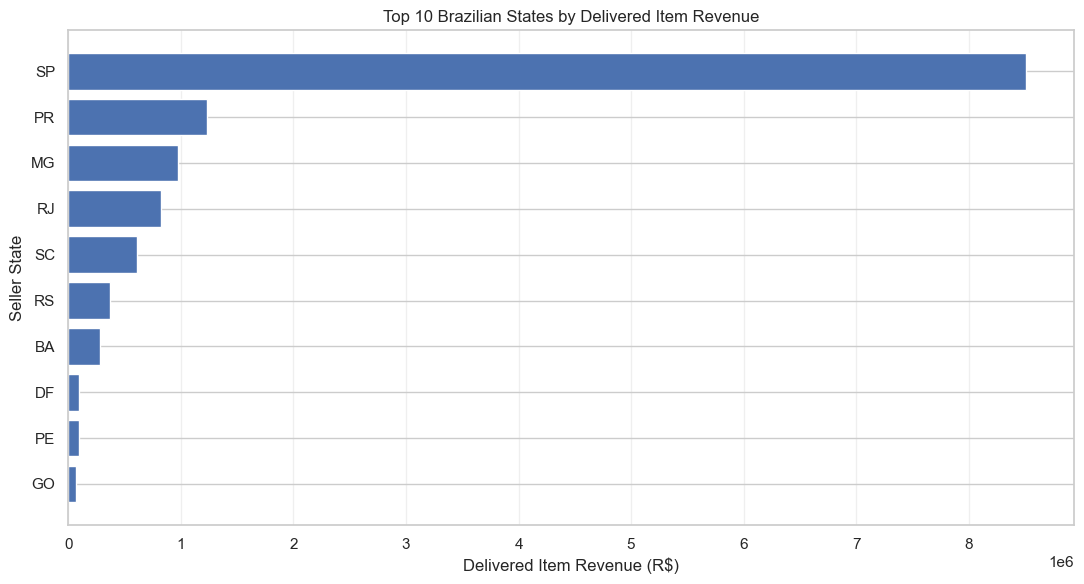

In [56]:
top_states = state_analysis.head(10).sort_values(
    "total_revenue"
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_states.index,
    top_states["total_revenue"]
)

plt.title("Top 10 Brazilian States by Delivered Item Revenue")
plt.xlabel("Delivered Item Revenue (R$)")
plt.ylabel("Seller State")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
# Calculate revenue contribution by seller ranking
seller_concentration = {}

for n in [1, 5, 10, 20, 50]:
    revenue = seller_analysis.head(n)["total_revenue"].sum()

    seller_concentration[f"Top {n} Sellers"] = round(
        revenue / total_delivered_revenue * 100, 2
    )

pd.Series(seller_concentration, name="Revenue Contribution (%)")

Top 1 Sellers     1.72
Top 5 Sellers     7.71
Top 10 Sellers   13.27
Top 20 Sellers   21.28
Top 50 Sellers   33.20
Name: Revenue Contribution (%), dtype: float64

In [58]:
# Seller-level performance by state
state_seller_summary = (
    seller_analysis
    .groupby("seller_state")
    .agg(
        total_sellers=("seller_id", "nunique"),
        total_revenue=("total_revenue", "sum"),
        average_revenue_per_seller=("total_revenue", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)

state_seller_summary["revenue_percentage"] = (
    state_seller_summary["total_revenue"] /
    total_delivered_revenue * 100
)

state_seller_summary = state_seller_summary.round(2)

display(state_seller_summary.head(10))

,total_sellers,total_revenue,average_revenue_per_seller,revenue_percentage
seller_state,,,,
SP,1769,8509511.46,4810.35,64.36
PR,335,1232096.99,3677.90,9.32
MG,236,977866.31,4143.50,7.40
RJ,163,820611.59,5034.43,6.21
SC,184,613591.65,3334.74,4.64
RS,125,373412.08,2987.30,2.82
BA,18,277925.51,15440.31,2.10
DF,30,94840.31,3161.34,0.72
PE,9,91164.15,10129.35,0.69


In [59]:
import pandas as pd
from pathlib import Path

# Create dashboard output folder
PROJECT_DIR = Path.cwd()
DASHBOARD_DIR = PROJECT_DIR / "dashboard"
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------------------
# 1. EXECUTIVE KPIs
# -----------------------------------------

total_delivered_orders = orders_clean.loc[
    orders_clean["order_status"] == "delivered",
    "order_id"
].nunique()

total_delivered_revenue = delivered_items_category["price"].sum()

average_order_value = (
    delivered_items_category
    .groupby("order_id")["price"]
    .sum()
    .mean()
)

average_review_score = (
    delivery_reviews["average_review_score"].mean()
)

average_delivery_days = (
    delivery_analysis["actual_delivery_days"].mean()
)

late_delivery_percentage = (
    delivery_analysis["delivery_status"].eq("Late").mean() * 100
)

on_time_percentage = 100 - late_delivery_percentage

executive_kpis = pd.DataFrame([{
    "total_delivered_orders": total_delivered_orders,
    "total_delivered_revenue": round(total_delivered_revenue, 2),
    "average_order_value": round(average_order_value, 2),
    "average_review_score": round(average_review_score, 2),
    "average_delivery_days": round(average_delivery_days, 2),
    "late_delivery_percentage": round(late_delivery_percentage, 2),
    "on_time_percentage": round(on_time_percentage, 2)
}])


# -----------------------------------------
# 2. MONTHLY SALES
# -----------------------------------------

monthly_data = order_overview[
    order_overview["order_status"] == "delivered"
].copy()

monthly_data["purchase_month"] = (
    monthly_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_sales_dashboard = (
    monthly_data
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        revenue=("item_revenue", "sum")
    )
    .reset_index()
)

all_months = pd.date_range(
    start=monthly_sales_dashboard["purchase_month"].min(),
    end=monthly_sales_dashboard["purchase_month"].max(),
    freq="MS"
)

monthly_sales_dashboard = (
    monthly_sales_dashboard
    .set_index("purchase_month")
    .reindex(all_months, fill_value=0)
    .rename_axis("purchase_month")
    .reset_index()
)

monthly_sales_dashboard["revenue"] = (
    monthly_sales_dashboard["revenue"].round(2)
)


# -----------------------------------------
# 3. DELIVERY & CUSTOMER SATISFACTION
# -----------------------------------------

delivery_satisfaction = (
    delivery_reviews
    .groupby("delivery_status")
    .agg(
        total_orders=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean"),
        median_review_score=("average_review_score", "median"),
        average_delivery_days=("actual_delivery_days", "mean"),
        average_delay_days=("delivery_delay_days", "mean")
    )
    .reset_index()
    .round(2)
)


# -----------------------------------------
# 4. PRODUCT CATEGORY PERFORMANCE
# -----------------------------------------

category_performance = (
    delivered_items_category
    .assign(
        product_category_name_english=
        delivered_items_category[
            "product_category_name_english"
        ].fillna("Unknown")
    )
    .groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        total_items=("order_item_id", "count"),
        average_item_price=("price", "mean")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
    .round(2)
)


# -----------------------------------------
# 5. STATE PERFORMANCE
# -----------------------------------------

state_performance = (
    seller_analysis
    .groupby("seller_state")
    .agg(
        total_sellers=("seller_id", "nunique"),
        total_revenue=("total_revenue", "sum"),
        average_revenue_per_seller=("total_revenue", "mean")
    )
    .reset_index()
)

state_performance["revenue_percentage"] = (
    state_performance["total_revenue"] /
    total_delivered_revenue * 100
)

state_performance = (
    state_performance
    .sort_values("total_revenue", ascending=False)
    .round(2)
)


# -----------------------------------------
# 6. SELLER CONCENTRATION
# -----------------------------------------

seller_concentration_dashboard = pd.DataFrame([
    {
        "seller_group": f"Top {n} Sellers",
        "seller_count": n,
        "total_revenue": seller_analysis.head(n)["total_revenue"].sum(),
        "revenue_percentage": (
            seller_analysis.head(n)["total_revenue"].sum()
            / total_delivered_revenue * 100
        )
    }
    for n in [1, 5, 10, 20, 50]
])

seller_concentration_dashboard = (
    seller_concentration_dashboard.round(2)
)


# -----------------------------------------
# 7. EXPORT ALL TABLES TO ONE EXCEL FILE
# -----------------------------------------

output_file = DASHBOARD_DIR / "Olist_Looker_Studio_Data.xlsx"

dashboard_tables = {
    "Executive_KPIs": executive_kpis,
    "Monthly_Sales": monthly_sales_dashboard,
    "Delivery_Satisfaction": delivery_satisfaction,
    "Category_Performance": category_performance,
    "State_Performance": state_performance,
    "Seller_Concentration": seller_concentration_dashboard
}

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    for sheet_name, dataframe in dashboard_tables.items():
        dataframe.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

print("Dashboard data exported successfully!")
print("File location:", output_file)

for sheet_name, dataframe in dashboard_tables.items():
    print(sheet_name, ":", dataframe.shape)

Dashboard data exported successfully!
File location: C:\Users\konic\Olist_Capstone_Analysis\dashboard\Olist_Looker_Studio_Data.xlsx
Executive_KPIs : (1, 7)
Monthly_Sales : (24, 3)
Delivery_Satisfaction : (2, 6)
Category_Performance : (72, 4)
State_Performance : (22, 5)
Seller_Concentration : (5, 4)
